In [ ]:
import pandas as pd 

# read each month of divvy data going back one calendar year
Nov = pd.read_csv('data/Divvy Data/202511-divvy-tripdata.csv')
Dec = pd.read_csv('data/Divvy Data/202512-divvy-tripdata.csv')
Jan = pd.read_csv('data/Divvy Data/202601-divvy-tripdata.csv')
Feb = pd.read_csv('data/Divvy Data/202602-divvy-tripdata.csv')
Mar = pd.read_csv('data/Divvy Data/202603-divvy-tripdata.csv')
Apr = pd.read_csv('data/Divvy Data/202604-divvy-tripdata.csv')
May = pd.read_csv('data/Divvy Data/202605-divvy-tripdata.csv')
Jun = pd.read_csv('data/Divvy Data/202606-divvy-tripdata.csv')
Jul = pd.read_csv('data/Divvy Data/202607-divvy-tripdata.csv')
Aug = pd.read_csv('data/Divvy Data/202608-divvy-tripdata.csv')
Sep = pd.read_csv('data/Divvy Data/202609-divvy-tripdata.csv')
Oct = pd.read_csv('data/Divvy Data/202610-divvy-tripdata.csv')





In [ ]:
# combine each month into one df,  convert dates to datetime
rides = pd.concat(
    [Nov, Dec, Jan, Feb, Mar, Apr, May, Jun, Jul, Aug, Sep, Oct], 
ignore_index = True) 


rides['started_at'] = pd.to_datetime(rides['started_at'])

rides['ended_at'] = pd.to_datetime(rides['ended_at'])



In [ ]:
# Cubs data source
# https://www.google.com/url?sa=t&source=web&rct=j&opi=89978449&url=https://www.mlb.com/cubs/schedule/downloadable-schedule&ved=2ahUKEwiFw6Gz8JKYAxWIN4YAHQUQGPoQFnoECB8QAQ&usg=AOvVaw0pq6KeoTn26KI0j57L_tHs

#Bulls, Bears data source
#fixturedownload.com

In [ ]:
# Read the Bears data sets and combine them
B1 = pd.read_csv('data/bears1.csv')
B2 = pd.read_csv('data/bears2.csv')

NFL = pd.concat([B1, B2], ignore_index=True)

# Filter to Home games
Home = (NFL['Location'] == 'Soldier Field') 
Bears = NFL[Home].copy()

# Convert dates to datetime
Bears['Date'] = pd.to_datetime(Bears['Date'], format='%d/%m/%Y %H:%M', utc=True)    
Bears['Date'] = Bears['Date'].dt.tz_convert('America/Chicago')

# filter for games within the window (going back one calendar year)
start = pd.Timestamp("2025-11-01", tz="America/Chicago")
end = pd.Timestamp("2026-11-01", tz="America/Chicago")   

Bears = Bears[(Bears['Date'] >= start) & (Bears['Date'] < end)]
print(len(Bears))


11


In [ ]:
# Read Bulls data, filter for home games, convert dates to datetime, and filter to within the window
NBA = pd.read_csv('data/Bulls.csv')
Home2 = (NBA['Location'] =='United Center')
Bulls = NBA[Home2].copy()

Bulls['Date'] = pd.to_datetime(Bulls['Date'], format = '%d/%m/%Y %H:%M', utc = True)
Bulls['Date'] = Bulls['Date'].dt.tz_convert('America/Chicago')

Bulls = Bulls[(Bulls['Date'] >= start) & (Bulls['Date'] < end)]
print(len(Bulls))

37


In [ ]:
# Read Cubs data, filter for home games, convert dates to datetime, and filter to within the window
Cubs = pd.read_csv('data/Cubs.csv')

Cubs['START DATE'] = pd.to_datetime(
    Cubs['START DATE'] + ' ' + Cubs['START TIME'],
    format='%m/%d/%y %I:%M %p'
)
Cubs['START DATE'] = Cubs['START DATE'].dt.tz_localize('America/Chicago')

Cubs = Cubs[(Cubs['START DATE'] >= start) & (Cubs['START DATE'] < end)]
print(len(Cubs))

81


In [ ]:
# Definen locations for each sports venue
Wrigley = [41.9484 , -87.6558]
Soldier = [41.8623, -87.6167]
United = [41.880692, -87.674370]


In [ ]:
# Check missing values 
missing_percent = rides.isna().mean() * 100
missing_percent.sort_values(ascending=False).round(1)


end_station_name      21.7
end_station_id        21.7
start_station_name    20.7
start_station_id      20.7
end_lat                0.1
end_lng                0.1
ride_id                0.0
rideable_type          0.0
started_at             0.0
ended_at               0.0
start_lat              0.0
start_lng              0.0
member_casual          0.0
dtype: float64

In [ ]:
# check where duplicates are, and drop exact duplicates
print(rides.duplicated(subset = ['ride_id']).sum())
print(rides.duplicated().sum())
rides = rides.drop_duplicates()
print(rides.duplicated(subset = ['ride_id']).sum())

35
35


In [ ]:
# Checks to make sure everything is within the window, and there are no impossible lat/long values
print(rides['started_at'].min())
print(rides['started_at'].max())

rides['month'] = rides['started_at'].dt.month


print(rides['start_lat'].max())
print(rides['start_lat'].min())
print(rides['start_lng'].max())
print(rides['start_lng'].min())

print(rides['end_lat'].max())
print(rides['end_lat'].min())
print(rides['end_lng'].max())
print(rides['end_lng'].min())




2025-10-31 01:24:38.549000
2026-10-31 23:59:45.105000
42.07
41.64
-87.52
-87.91
42.19
41.51
-87.37
-88.1


In [ ]:
# Remove any impossible trips which end before they start
valid = (rides['ended_at'] > rides['started_at']) 

rides = rides[valid].copy()

# Create a new variable representing the duration of a trip
rides['duration'] = rides['ended_at'] - rides['started_at']
rides['duration_min'] = rides['duration'].dt.total_seconds() / 60

# Filter outlier trips that were less than 1 minute, and longer than 240. Combined, these trips only account for around 2.7 % of trips
print(rides['duration_min'].describe())
too_short = rides['duration_min'] < 1
too_long = rides['duration_min'] > 240 

print(len(rides[too_long]) / len(rides) * 100)
print(len(rides[too_short]) / len(rides) * 100)

keep = ~(too_short | too_long)
rides = rides[keep].copy()

print(rides['duration_min'].describe()) 


count    6.294387e+06
mean     1.506885e+01
std      4.991845e+01
min      9.333333e-04
25%      5.304467e+00
50%      9.197633e+00
75%      1.602335e+01
max      1.559950e+03
Name: duration_min, dtype: float64
0.17676065993400153
2.5362755737770812
count    6.123618e+06
mean     1.361576e+01
std      1.493139e+01
min      1.000000e+00
25%      5.562567e+00
50%      9.421958e+00
75%      1.623335e+01
max      2.398880e+02
Name: duration_min, dtype: float64


In [ ]:
# Remove trips missing a station id. To measure departures by station, dockless trips must be removed. 
# Dockless trips were around 20% of the trips, though, and is a limitation of my analysis. 
# Create a normalized date col
known_station_id = rides.dropna(subset = 'start_station_id').copy()
known_station_id['date'] = known_station_id['started_at'].dt.normalize()

# Create a table of trips by station. Median lat/long in case some coords vary slightly. 
# First and last dates included to tell when a station was active. 
stations = known_station_id.groupby('start_station_id').agg(
    Station_name= ('start_station_name', 'first'),
    median_lat = ('start_lat' , 'median'), 
    median_lng = ('start_lng', 'median'),
    total_rides = ('ride_id', 'count'), 
    first_date = ('started_at', 'min'),
    last_date = ('started_at', 'max')

)
stations = stations.reset_index()

# Convert dates so they will match with the dates in the other dfs. 
stations['first_date'] = stations['first_date'].dt.normalize()
stations['last_date'] = stations['last_date'].dt.normalize()

# Chack that stations matches the number of unique known stations. 
print(len(stations) == known_station_id['start_station_id'].nunique())






True


In [13]:
stations.head(5) 






,start_station_id,Station_name,n_names,median_lat,median_lng,total_rides,first_date,last_date
0,CHI02331,Franklin St & Randolph St,1,41.884390,-87.635170,632,2026-05-15,2026-06-30
1,CHI00005,Milwaukee Ave & Wabansia Ave,1,41.912616,-87.681469,6321,2025-12-11,2026-10-31
2,CHI00213,Archer Ave & 43rd St,1,41.815491,-87.702441,11,2025-11-07,2026-03-13
3,CHI00214,Campbell Ave & Montrose Ave,1,41.961524,-87.691177,3819,2025-11-01,2026-10-31
4,CHI00215,Avondale Ave & Irving Park Rd,1,41.953393,-87.732002,2467,2025-11-01,2026-10-31


In [ ]:
from haversine import Unit, haversine

# create a new variable that measures the haversine distance between each station and each sports venue

stations['dist_SF'] = stations.apply(
    lambda row: haversine(list((row['median_lat'], row['median_lng'])) , Soldier, unit = Unit.MILES), 
    axis = 1
)
stations['dist_Wrig'] = stations.apply(
    lambda row: haversine(list((row['median_lat'], row['median_lng'])) , Wrigley, unit = Unit.MILES), 
        axis = 1
)
stations['dist_UC'] = stations.apply(
    lambda row: haversine(list((row['median_lat'], row['median_lng'])) , United, unit = Unit.MILES), 
        axis = 1
)
stations.head(5)

,start_station_id,Station_name,n_names,median_lat,median_lng,total_rides,first_date,last_date,dist_SF,dist_Wrig,dist_UC
0,CHI02331,Franklin St & Randolph St,1,41.884390,-87.635170,632,2026-05-15,2026-06-30,1.797914,4.548079,2.032614
1,CHI00005,Milwaukee Ave & Wabansia Ave,1,41.912616,-87.681469,6321,2025-12-11,2026-10-31,4.815099,2.802481,2.235750
2,CHI00213,Archer Ave & 43rd St,1,41.815491,-87.702441,11,2025-11-07,2026-03-13,5.471747,9.491377,4.730951
3,CHI00214,Campbell Ave & Montrose Ave,1,41.961524,-87.691177,3819,2025-11-01,2026-10-31,7.852731,2.031387,5.651402
4,CHI00215,Avondale Ave & Irving Park Rd,1,41.953393,-87.732002,2467,2025-11-01,2026-10-31,8.646703,3.930885,5.831965


In [15]:
print(Bears.sample(1))
print('___________________________________________')
print(Bulls.sample(1))
print('___________________________________________')
print(Cubs.sample(1))

    Match Number Round Number                      Date       Location  \
21            48            3 2026-09-28 19:15:00-05:00  Soldier Field   

        Home Team            Away Team  Result  
21  Chicago Bears  Philadelphia Eagles  27 - 7  
___________________________________________
    Match Number  Round Number                      Date       Location  \
70          1042            20 2026-03-23 19:00:00-05:00  United Center   

        Home Team        Away Team     Result  
70  Chicago Bulls  Houston Rockets  132 - 124  
___________________________________________
                  START DATE START TIME START TIME ET          SUBJECT  \
25 2026-05-20 18:40:00-05:00   06:40 PM      07:40 PM  Brewers at Cubs   

                   LOCATION  \
25  Wrigley Field - Chicago   

                                          DESCRIPTION  END DATE END DATE ET  \
25  Local TV: Marquee Sports Network ----- Local R...  05/20/26    05/20/26   

    END TIME END TIME ET  REMINDER OFF  REMINDE

In [ ]:
# Remove the unnecessary cols from each Team's dataset
Cubs = Cubs.rename(columns = {'LOCATION': 'Location', 'START DATE': 'Date'})
Cubs['Home Team'] = 'Chicago Cubs'
Cubs = Cubs.drop(columns = ['START TIME', 'START TIME ET', 'SUBJECT', 'DESCRIPTION', 'END DATE', 'END DATE ET', 'END TIME', 'END TIME ET', 
                            'REMINDER OFF', 'REMINDER ON', 'REMINDER DATE', 'REMINDER TIME', 'REMINDER TIME ET', 'SHOWTIMEAS FREE', 'SHOWTIMEAS BUSY'])
Bears = Bears.drop(columns = ['Match Number', 'Round Number', 'Away Team', 'Result'])
Bulls = Bulls.drop(columns = ['Match Number', 'Round Number', 'Away Team', 'Result'])



In [ ]:
# Combine the games into one data set, and normalize the date
Sports = pd.concat([Bears, Bulls, Cubs], ignore_index=True)

Sports['date'] = Sports['Date'].dt.tz_localize(None).dt.normalize()

Sports.sample(5)

,Date,Location,Home Team,date
106,2026-08-06 13:20:00-05:00,Wrigley Field - Chicago,Chicago Cubs,2026-08-06
123,2026-09-14 18:40:00-05:00,Wrigley Field - Chicago,Chicago Cubs,2026-09-14
41,2026-03-16 19:00:00-05:00,United Center,Chicago Bulls,2026-03-16
90,2026-07-01 13:20:00-05:00,Wrigley Field - Chicago,Chicago Cubs,2026-07-01
73,2026-05-20 18:40:00-05:00,Wrigley Field - Chicago,Chicago Cubs,2026-05-20


In [ ]:
# Create a df to analyze departures by station

df = known_station_id.groupby(['start_station_id', 'date']).agg(
    departures = ('ride_id', 'count'), 
)
df = df.reset_index()





In [ ]:
# Create flags for stations within .5 miles of each venue
radius = .5

stations['near_SF']   = stations['dist_SF']   <= radius
stations['near_Wrig'] = stations['dist_Wrig'] <= radius
stations['near_UC']   = stations['dist_UC']   <= radius

print(stations[['near_SF', 'near_Wrig', 'near_UC']].sum())



near_SF       7
near_Wrig    29
near_UC       7
dtype: int64
300248 12700


In [20]:
stations.sample(3)

,start_station_id,Station_name,n_names,median_lat,median_lng,total_rides,first_date,last_date,dist_SF,dist_Wrig,dist_UC,near_SF,near_Wrig,near_UC
566,CHI00805,Narragansett Ave & McLean Ave,1,41.915900,-87.785110,81,2025-11-04,2026-10-31,9.420759,7.015752,6.192966,False,False,False
325,CHI00538,Pulaski Rd & Eddy St,1,41.946264,-87.731023,824,2025-11-01,2026-10-31,8.259370,3.868443,5.386200,False,False,False
709,CHI00963,LaSalle St & Adams St Corral,1,41.879380,-87.632080,64,2025-11-02,2026-01-08,1.420860,4.922307,2.177417,False,False,False


In [ ]:
# create a df of each date within my window to match with stations near each venue
window = pd.date_range(start="2025-11-01", end="2026-10-31", freq="D")
days = pd.DataFrame({'date':window})
nearby = stations[stations[['near_SF', 'near_Wrig', 'near_UC']].any(axis = 1)].copy()
grid = nearby.merge(days, how = 'cross')

# Keep only dates within when each station was active, then fill days with no trips as 0 departures. 
active = ((grid['date'] >= grid['first_date']) & (grid['date'] <= grid['last_date']))
grid = grid[active].copy()
new_grid = grid.merge(df[['start_station_id', 'date', 'departures']], on = ['start_station_id', 'date'], how = 'left')
new_grid['departures'] = (new_grid['departures'].fillna(0)).astype(int)
new_grid['month'] = new_grid['date'].dt.month



In [ ]:
# Obtain gameday dates for each team

cubs_dates = Sports.loc[Sports['Home Team'] == 'Chicago Cubs', 'date']
event_Wrig = new_grid['near_Wrig'] & new_grid['date'].isin(cubs_dates)


bears_dates = Sports.loc[Sports['Home Team'] == 'Chicago Bears', 'date']
event_SF = new_grid['near_SF'] & new_grid['date'].isin(bears_dates)


bulls_dates = Sports.loc[Sports['Home Team'] == 'Chicago Bulls', 'date']
event_UC = new_grid['near_UC'] & new_grid['date'].isin(bulls_dates)

# create a new col representing whether or not that day was a gameday for any venue
new_grid['is_event'] = event_SF | event_UC | event_Wrig



In [ ]:
# Get normal days and define a baseline number of departures by station by month
normal_days = new_grid[~new_grid['is_event']] 

baseline = normal_days.groupby(['start_station_id', 'month']).agg(
    base_departures = ('departures', 'mean'),
    n_days = ('date', 'count')
)
baseline = baseline.reset_index()

event_days = new_grid[new_grid['is_event']]

# merge the baseline df and the event_day line for analysis

base_vs_event = event_days.merge(baseline, on = ['start_station_id','month'], how = 'left')



In [ ]:
# Check how manyinstances where a station had 0 departures 
zero = base_vs_event['base_departures'] == 0 
print(zero.sum())
# Remove them to avoid a divide by zero error
base_vs_event = base_vs_event.loc[base_vs_event['base_departures']> 0].copy()

# Calculate the percent change in departures on a gameday compared to a baseline day
base_vs_event['pct_lift'] = ((base_vs_event['departures'] - base_vs_event['base_departures']) / base_vs_event['base_departures']) * 100


5


In [ ]:
import numpy as np

# label each event row with a team based on which venue flag it is near
conditions = [base_vs_event['near_SF'], base_vs_event['near_UC'], base_vs_event['near_Wrig']]
name = ['Bears', 'Bulls', 'Cubs']
base_vs_event['team'] = np.select(conditions, name, default = 'Other')

# make sure no team got an 'Other' label
base_vs_event['team'].value_counts()


team
Cubs     2239
Bulls     222
Bears      77
Name: count, dtype: int64

In [ ]:
# Measure lift by team
lift = base_vs_event.groupby('team').agg(
    median_lift = ('pct_lift', 'median'),
    mean_lift = ('pct_lift', 'mean'),
    lift_counts = ('pct_lift', 'count')
)

lift.head(3)

,median_lift,mean_lift,lift_counts
team,,,
Bears,41.996830,193.498962,77
Bulls,-24.926108,2.326837,222
Cubs,59.813084,452.322855,2239


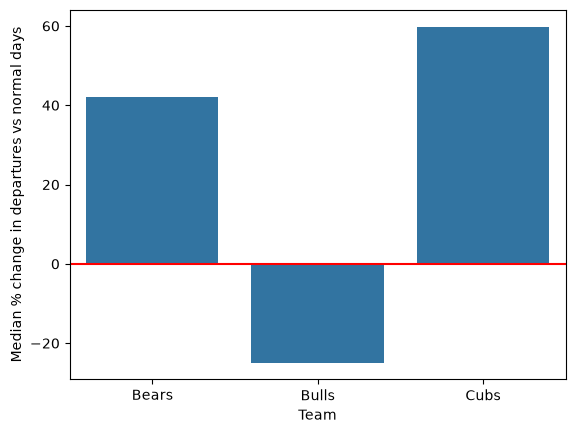

In [ ]:
import seaborn as sns 
import matplotlib.pyplot as plt

# plot median pct change in lift by team
sns.barplot(data = lift, x = 'team', y = 'median_lift')
plt.ylabel('Median % change in departures vs normal days')
plt.xlabel('Team')
plt.axhline(color = 'red')
plt.show()

On a Cubs gameday, nearby stations see about 60% more departures compared to a non gameday
On a Bears gameday, nearby stations see about 40% more departures compared to a non gameday
On a Bulls gameday, nearby stations see about 20% less departures compared to a non gameday. 

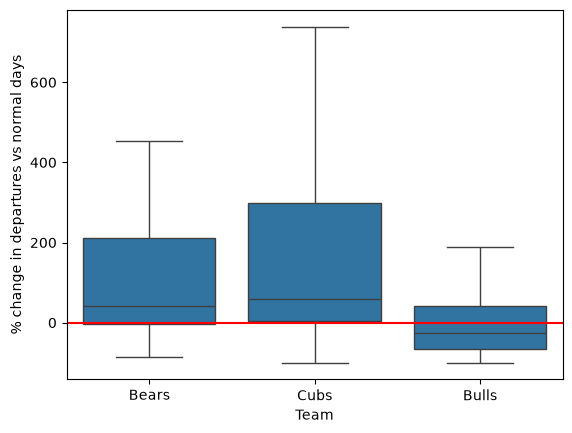

In [ ]:
# plot % change in departures vs normal days by team

sns.boxplot(data = base_vs_event, x = 'team', y = 'pct_lift', showfliers = False)
plt.ylabel('% change in departures vs normal days')
plt.xlabel('Team')
plt.axhline(color = 'red')
plt.show()

For at least 3 quarters of gamedays for stations near Soldier Field and Wrigley, There are more gameday departures than normal day departures. 

For Bulls gamedays, gameday departures fall below the baseline, but the effect is inconsistent. 


